In [36]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

df = pd.read_csv('hanoi_dataset.csv')
print(df.shape)
df.head(10)

(300, 6)


,n_disks,move_count,exec_time_ms,log2_moves,recursion_depth,complexity
0,1,1,0.0077,1.0,1,Low
1,2,3,0.0144,2.0,2,Low
2,3,7,0.0124,3.0,3,Low
3,4,15,0.0206,4.0,4,Low
4,5,31,0.0362,5.0,5,Low
5,6,63,0.0699,6.0,6,Low
6,7,127,0.1430,7.0,7,Medium
7,8,255,0.3314,8.0,8,Medium
8,9,511,0.6398,9.0,9,Medium
9,10,1023,1.4854,10.0,10,Medium


In [37]:
# Dataset Info
print(df['complexity'].value_counts())
print(df.describe())

complexity
Medium    105
High      105
Low        90
Name: count, dtype: int64
          n_disks    move_count  exec_time_ms  log2_moves  recursion_depth
count  300.000000  3.000000e+02    300.000000  300.000000       300.000000
mean    10.500000  1.048565e+05     83.281266   10.500000        10.500000
std      5.775916  2.500281e+05    204.952421    5.775916         5.775916
min      1.000000  1.000000e+00      0.002700    1.000000         1.000000
25%      5.750000  5.500000e+01      0.034975    5.750000         5.750000
50%     10.500000  1.535000e+03      1.869350   10.500000        10.500000
75%     15.250000  4.095900e+04     56.896100   15.250000        15.250000
max     20.000000  1.048575e+06   1498.076800   20.000000        20.000000


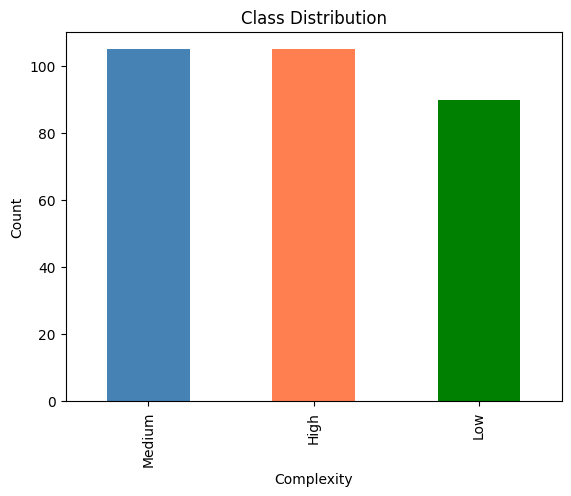

In [38]:
# Class Distribution
df['complexity'].value_counts().plot(kind='bar', color=['steelblue', 'coral', 'green'])
plt.title('Class Distribution')
plt.xlabel('Complexity')
plt.ylabel('Count')
plt.show()

In [39]:
# Data Split
X = df.drop(columns=['complexity'])
y = df['complexity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape[0], '  Test:', X_test.shape[0])

Train: 240   Test: 60


In [40]:
# Train Model
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print('Model trained.')

Model trained.


In [41]:
# Model Accuracy
train_acc = accuracy_score(y_train, clf.predict(X_train))
test_acc  = accuracy_score(y_test, y_pred)
print('Training Accuracy :', round(train_acc * 100, 2), '%')
print('Testing Accuracy  :', round(test_acc  * 100, 2), '%')

Training Accuracy : 100.0 %
Testing Accuracy  : 100.0 %


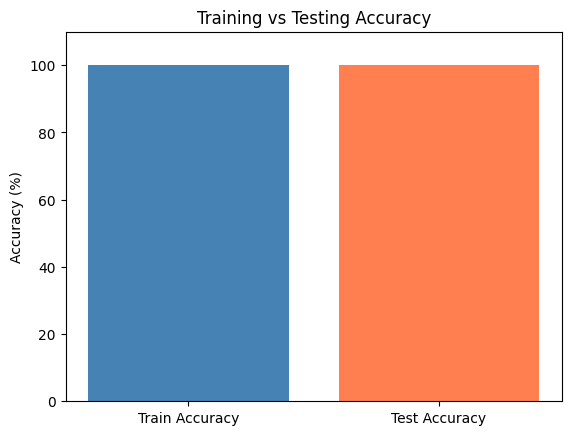

In [42]:
# Accuracy Chart
plt.bar(['Train Accuracy', 'Test Accuracy'], [train_acc * 100, test_acc * 100], color=['steelblue', 'coral'])
plt.title('Training vs Testing Accuracy')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 110)
plt.show()

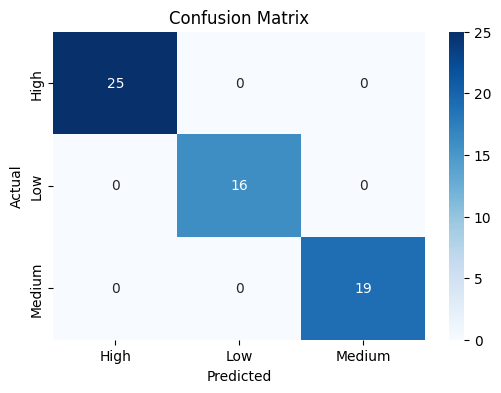

In [43]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [44]:
# Classification Report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       1.00      1.00      1.00        25
         Low       1.00      1.00      1.00        16
      Medium       1.00      1.00      1.00        19

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



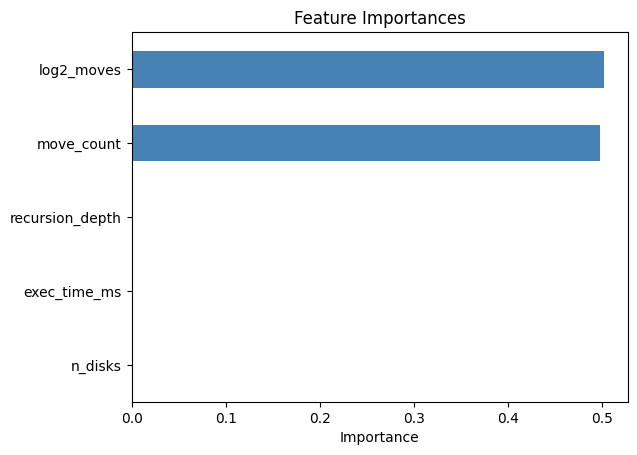

In [45]:
# Feature Importance
importances = pd.Series(clf.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh', color='steelblue')
plt.title('Feature Importances')
plt.xlabel('Importance')
plt.show()

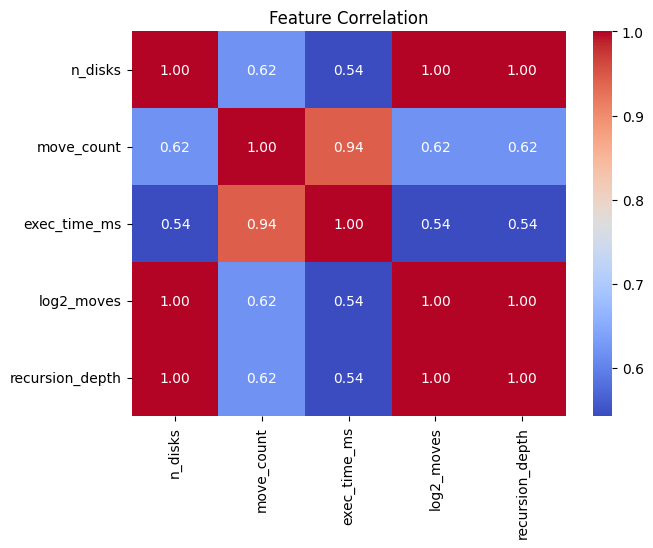

In [46]:
# Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(columns=['complexity']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation')
plt.show()

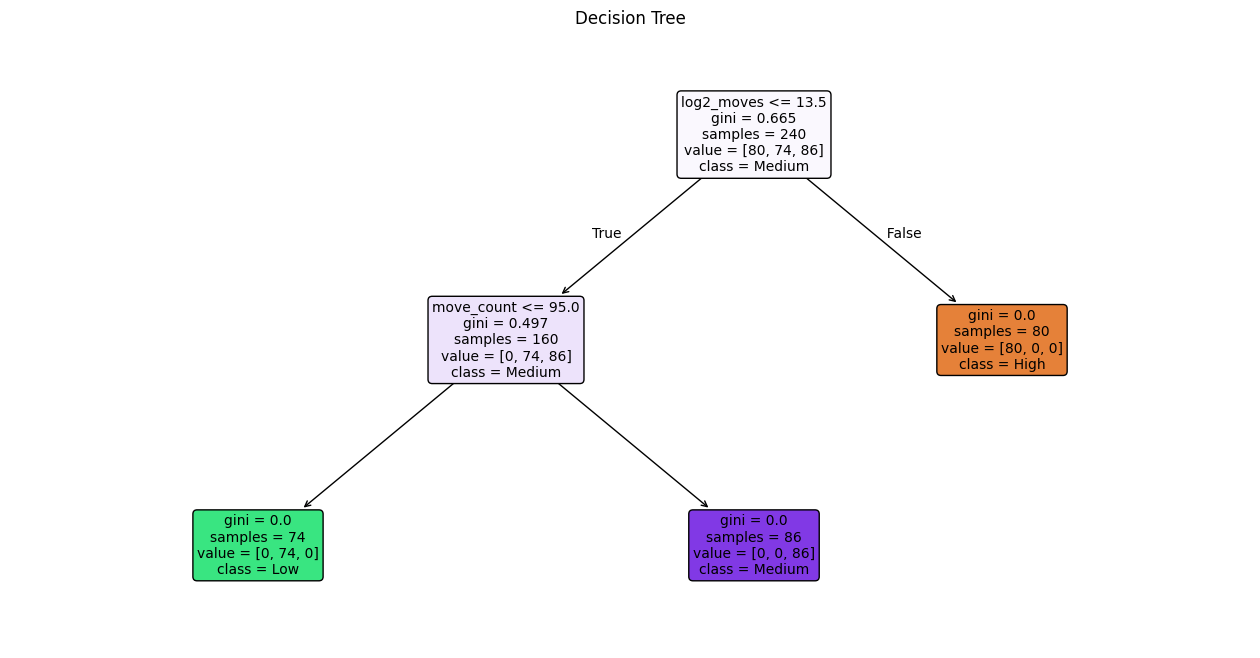

In [47]:
# Decision Tree
plt.figure(figsize=(16, 8))
plot_tree(
    clf,
    feature_names=list(X.columns),
    class_names=list(clf.classes_),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree')
plt.show()